In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

import os
from pathlib import Path
os.chdir(Path().cwd().parent.parent)

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from geo6.io.io import load_data
from geo6.plot.plot import save_plot
from geo6.config.config import Config

config = Config()

In [3]:
data = load_data()

## H1: Differences in microbial basal respiration
Do respiration rates differ between soil groups?

In [134]:
from geo6.plot.plot import save_plot, plot_basal_resp_boxplot, plot_basal_resp_rootextract_boxplot

### Basal respiration

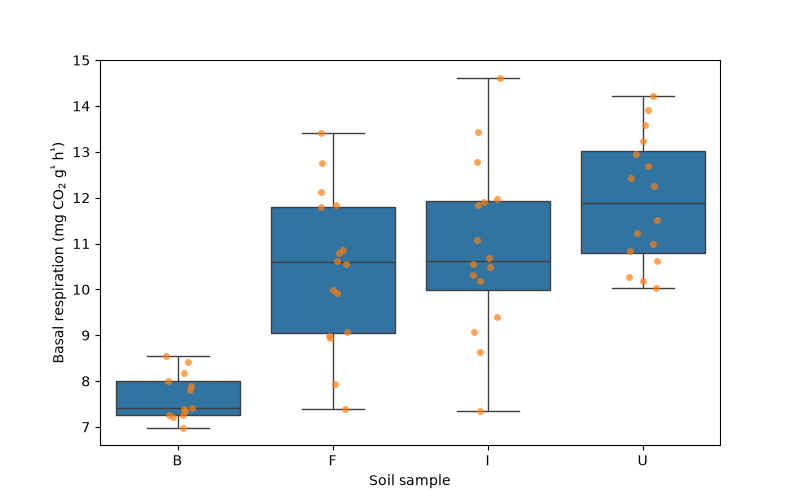

In [137]:
subset = microresp[["sample", "subrep", "br_mg_per_g_h"]]

plot = plot_basal_resp_boxplot(df=subset)
save_plot(plot=plot, name="basal_resp_boxplot")

No ANOVA since independence of variables is not given. We are measuring more the variance of the method than of the groups since we made one big mixture pot.

But if bulk was collected fro only one place this would explain the variance in the other groups and then show variance in sample location, rather than groups or masking those effects.

### Basal respiration root extract

In [22]:
subset = microresp[[
    'sample',
    "subrep",
    
    # 'br_mg_per_g_h',
    
    'br_I1_mg_per_g_h',
    'br_U1_mg_per_g_h',
    'br_F1_mg_per_g_h',
    
    'br_I2_mg_per_g_h',
    'br_U2_mg_per_g_h',
    'br_F2_mg_per_g_h',
]]

In [23]:
def melt_root_subset(df: pd.DataFrame) -> pd.DataFrame:
    respiration_cols = [
        col for col in df.columns
        if col.startswith("br_") and col.endswith("_mg_per_g_h")
    ]

    respiration = df.melt(
        id_vars=["sample", "subrep"],
        value_vars=respiration_cols,
        var_name="condition",
        value_name="respiration",
    ).dropna(subset=["respiration"])
    

    respiration[["extract", "concentration"]] = (
        respiration["condition"]
        .str.extract(r"br_([IUF])([12])_mg_per_g_h")
    )
    
    respiration["concentration"] = (
        respiration["concentration"].astype(int)
    )
    
    return respiration

subset_melt = melt_root_subset(df=subset)

# display(subset_melt)

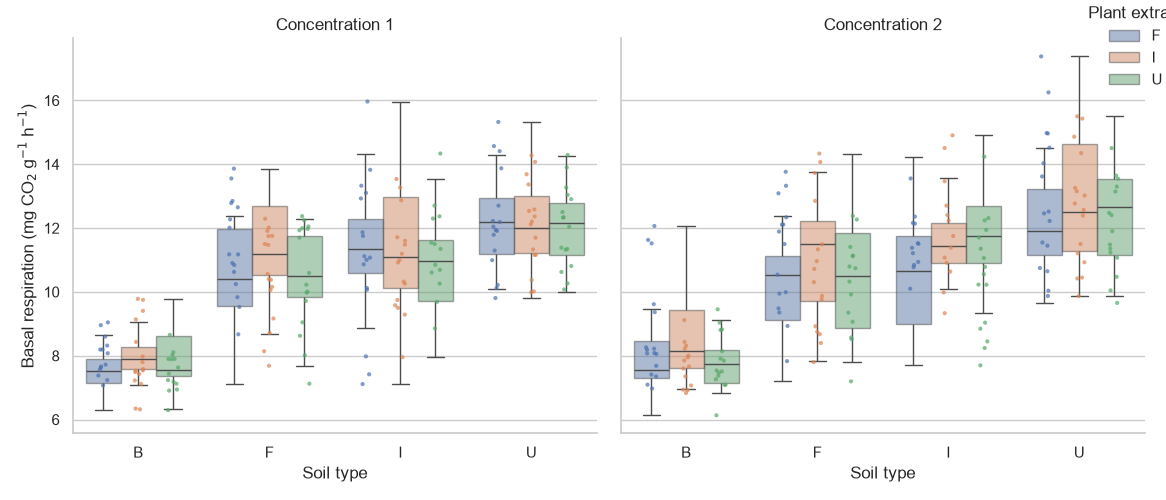

In [24]:
plot = plot_basal_resp_rootextract_boxplot(df=subset_melt)
save_plot(plot=plot, name="basal_resp_rootextract_boxplot")

## H2: Differences in substrate-use profiles

In [9]:
from geo6.plot.plot import save_plot, plot_sir_boxplots

In [10]:
microresp = data.microresp

subset = microresp[[
    "sample",
    'sir_1_mg_per_g_h',
    'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h',
    'sir_4_mg_per_g_h',
    'sir_5_mg_per_g_h',
    'sir_6_mg_per_g_h',
    'sir_7_mg_per_g_h',
    'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h',
    'sir_10_mg_per_g_h',
    'sir_11_mg_per_g_h',
]]

substance_mapping = {
    'sir_1_mg_per_g_h': "D-(+) Glucose",
    'sir_2_mg_per_g_h': "D-(+) Galactose",
    'sir_3_mg_per_g_h': "D-(+) Trehalose",
    'sir_4_mg_per_g_h': "a-Cyclodextrin",
    'sir_5_mg_per_g_h': "L-Alanine",
    'sir_6_mg_per_g_h': "L-Arginine",
    'sir_7_mg_per_g_h': "L-Phenylalanine",
    'sir_8_mg_per_g_h': "g-Amino buturic acid",
    'sir_9_mg_per_g_h': "Oxalic acid",
    'sir_10_mg_per_g_h': "Tri sodium citrat dihydrate",
    'sir_11_mg_per_g_h': "Lignin alkali",
}

subset_melt = subset.melt(id_vars = "sample")
subset_melt["substance"] = subset_melt["variable"].map(substance_mapping)

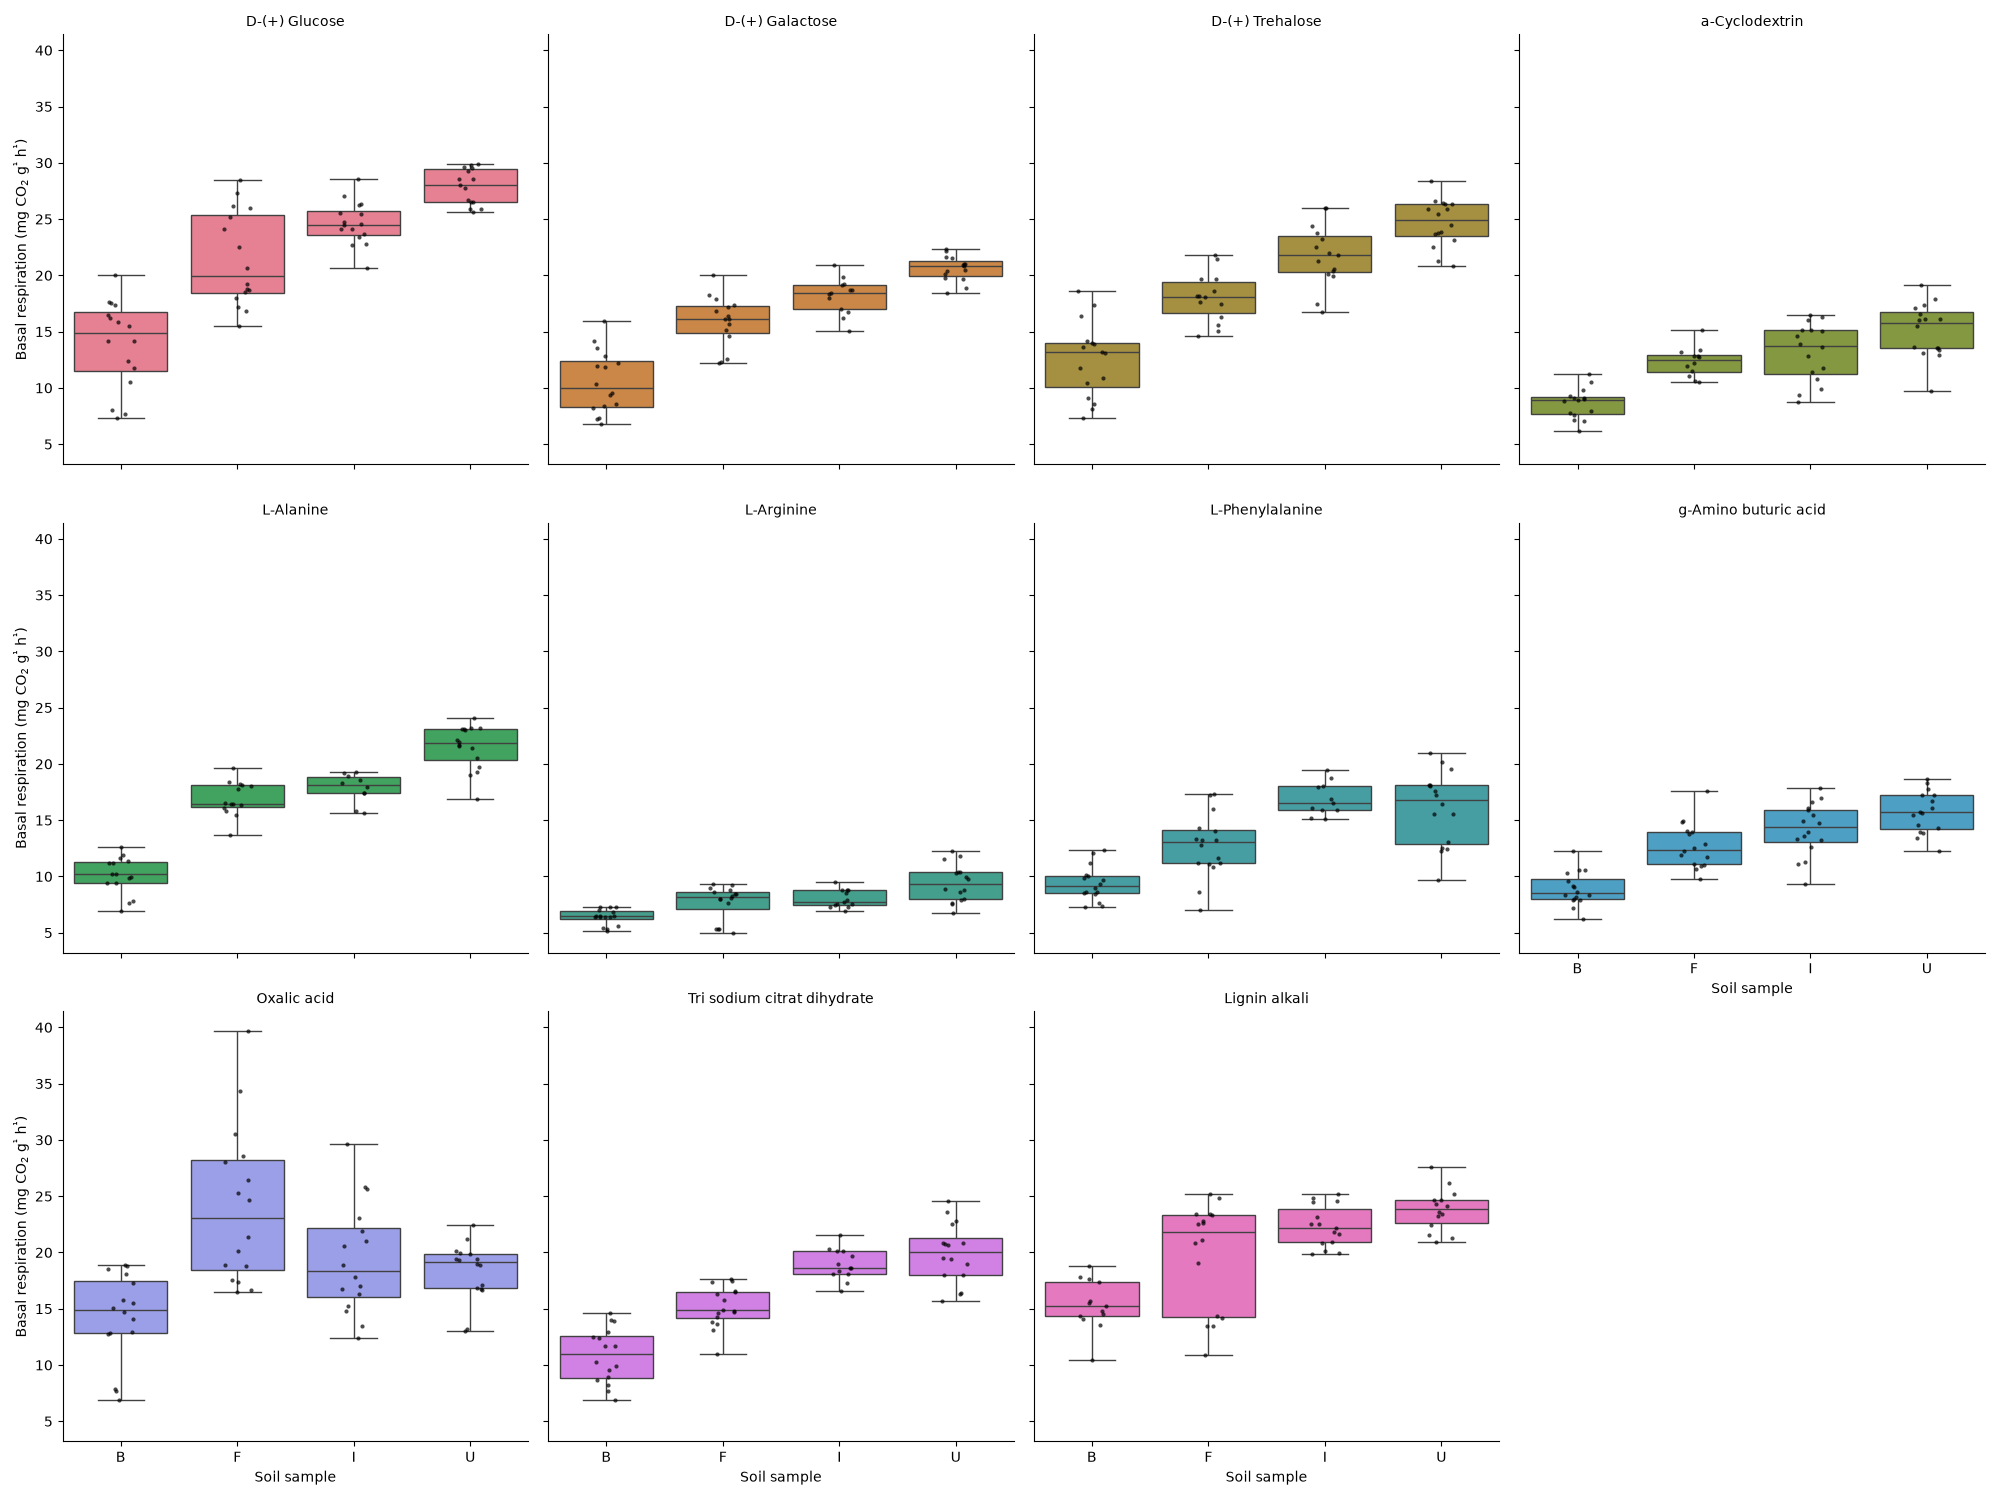

In [11]:
substance_list = list(substance_mapping.values())

plot = plot_sir_boxplots(df=subset_melt, mapping=substance_list)

save_plot(plot=plot, name="sir_boxplot")

## Check soil data

In [140]:
copper = data.copper
copper

,sample,type,group,subrep,cu_ex_ug_kg_dm,cu_red_ug_kg_dm,cu_org_ug_kg_dm
0,B,soil,1,NaN,0.000,3.148,15.848
1,F,soil,1,NaN,4.167,4.114,17.978
2,I,soil,1,NaN,0.000,1.337,13.093
3,U,soil,1,NaN,0.000,3.130,15.113
4,B,soil,2,NaN,1.682,12.039,41.956
5,F,soil,2,NaN,1.775,8.506,20.533
6,I,soil,2,NaN,0.458,11.624,51.369
7,U,soil,2,NaN,1.066,9.166,52.905
8,B,soil,3,NaN,15.184,12.428,42.763
9,F,soil,3,NaN,2.394,6.861,15.672


In [97]:
chns = data.chns
chns = chns[chns["type"] == "soil"]
subset = chns[["sample", "cn_ratio_percent"]].groupby("sample").mean()

In [112]:
chns

,sample,type,group,subrep,c_tot_percent,n_tot_percent,s_tot_percent,cn_ratio_percent
0,B,soil,1.0,NaN,2.81,0.24,0.07,11.489
1,F,soil,1.0,NaN,2.50,0.20,0.04,12.804
2,I,soil,1.0,NaN,3.92,0.32,0.07,12.172
3,U,soil,1.0,NaN,4.09,0.34,0.07,11.956
4,B,soil,2.0,NaN,2.92,0.25,0.04,11.477
5,F,soil,2.0,NaN,2.24,0.18,0.05,12.479
6,I,soil,2.0,NaN,3.91,0.32,0.05,12.188
7,U,soil,2.0,NaN,4.12,0.34,0.05,12.104
8,B,soil,3.0,NaN,2.81,0.24,0.05,11.597
9,F,soil,3.0,NaN,2.46,0.19,0.05,12.988


In [122]:
microresp_agg = (
    microresp[["sample", "group", "subrep", "br_mg_per_g_h"]]
    .groupby(["sample", "group"], as_index=False)
    .agg(mean_br=("br_mg_per_g_h", "mean"))
)

merged = microresp_agg.merge(
    chns[["sample", "group", "cn_ratio_percent"]], 
    how="inner"
)
merged

,sample,group,mean_br,cn_ratio_percent
0,B,1,7.728500,11.489
1,B,2,7.123500,11.477
2,B,3,8.076333,11.597
3,B,4,7.581500,11.626
4,F,1,10.347250,12.804
5,F,2,11.453500,12.479
6,F,3,8.310500,12.988
7,F,4,11.638250,12.865
8,I,1,11.569250,12.172
9,I,2,10.103750,12.188


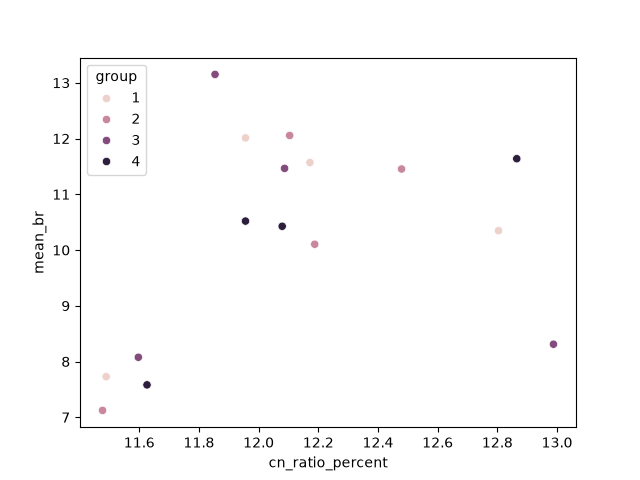

In [125]:
fig, ax = plt.subplots()

sns.scatterplot(
    data=merged,
    x="cn_ratio_percent",
    y="mean_br",
    hue="group"
)

plt.show()

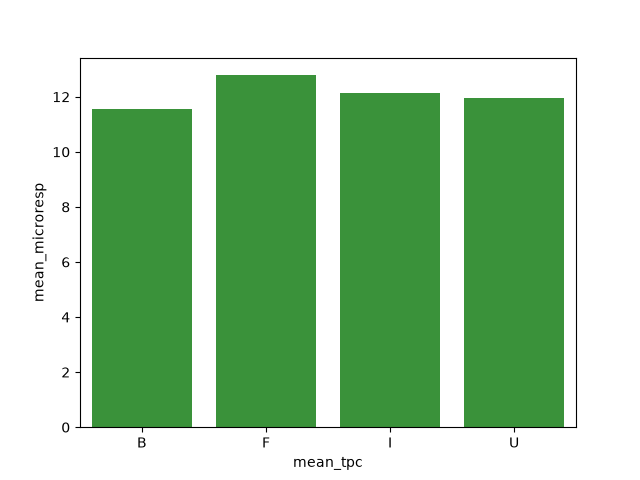

In [101]:
sns.barplot(
    data=subset,
    x="sample",
    y="cn_ratio_percent"
)

plt.show()

### TPC

In [14]:
tpc = data.total_phenolic_compounds.dropna()
tpc = tpc.drop(columns=["type", "group", "subrep"])
tpc.groupby("sample").mean()


,tpc_cacl_inc_ug_gae_kg_dm,tpc_cacl_froz_ug_gae_kg_dm,tpc_meoh_inc_ug_gae_kg_dm,tpc_meoh_froz_ug_gae_kg_dm
sample,,,,
B,2.6290,3.593,4.3740,4.6240
F,12.6170,7.363,3.9630,6.1420
I,3.5425,3.773,4.3065,4.5195
U,2.9050,4.332,5.1450,4.2740


In [34]:
tpc_agg = (
    data.total_phenolic_compounds[
        ["sample", "subrep", "tpc_cacl_froz_ug_gae_kg_dm"]
    ]
    .groupby(["sample", "subrep"], as_index=False)
    .agg(
        mean=("tpc_cacl_froz_ug_gae_kg_dm", "mean"),
        std=("tpc_cacl_froz_ug_gae_kg_dm", "std"),
        n=("tpc_cacl_froz_ug_gae_kg_dm", "count"),
    )
)
tpc_agg

,sample,subrep,mean,std,n
0,B,1,3.5930,0.000000,4
1,B,2,1.9310,0.000000,4
2,B,3,NaN,NaN,0
3,B,4,NaN,NaN,0
4,F,1,6.0860,0.000000,4
5,F,2,29.2792,49.006113,5
6,F,3,NaN,NaN,0
7,F,4,NaN,NaN,0
8,F,5,NaN,NaN,0
9,F,6,NaN,NaN,0


In [35]:
microresp_agg = (
    microresp[
        ["sample", "subrep", "br_mg_per_g_h"]
    ]
    .groupby(["sample", "subrep"], as_index=False)
    .agg(
        mean=("br_mg_per_g_h", "mean"),
        std=("br_mg_per_g_h", "std"),
        n=("br_mg_per_g_h", "count")
    )
)
microresp_agg

,sample,subrep,mean,std,n
0,B,1,7.745250,0.524211,4
1,B,2,7.349750,0.340422,4
2,B,3,7.993333,0.662737,3
3,B,4,7.678000,0.470933,2
4,F,1,10.497500,1.725586,4
5,F,2,9.525750,1.476791,4
6,F,3,11.734000,1.957206,4
7,F,4,9.992250,1.382217,4
8,I,1,9.997250,1.916854,4
9,I,2,10.534500,2.112728,4


In [47]:
merged = tpc_agg[["sample", "mean"]].merge(
    microresp_agg[["sample", "mean"]],
    on="sample",
    how="inner",
    suffixes=("_tpc", "_microresp"),
)
merged.dropna(inplace=True)

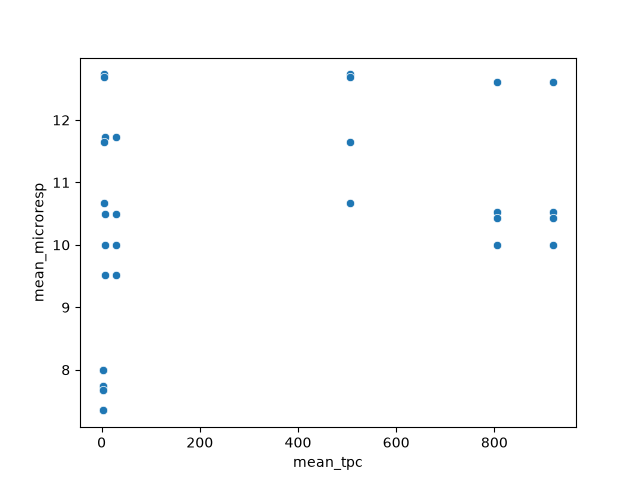

In [86]:
fig, ax = plt.subplots()

sns.scatterplot(
    data=merged,
    x="mean_tpc",
    y="mean_microresp",
    ax=ax,
)

plt.show()

### pH

In [4]:
subset = data.ph_cacl[["sample", "ph_cacl"]]

subset_agg = (
    subset
    .groupby("sample")["ph_cacl"]
    .agg(mean="mean", std="std")
    .reset_index()
)

In [99]:
subset_agg

,sample,mean,std
0,B,6.2550,0.042032
1,F,6.2925,0.083815
2,I,6.1950,0.081854
3,U,6.1575,0.120381


<Axes: xlabel='sample', ylabel='mean'>

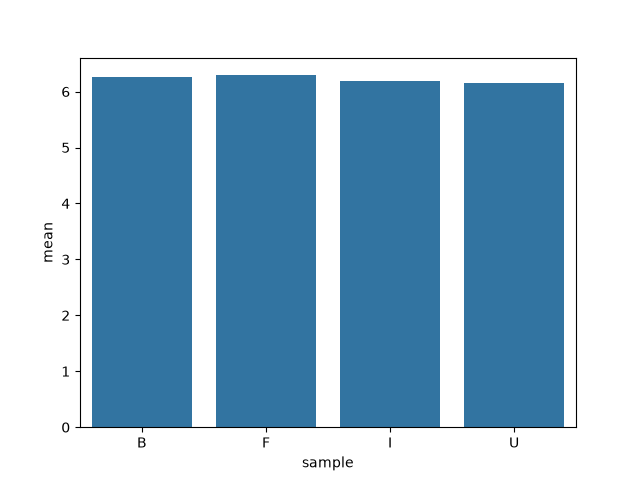

In [5]:
sns.barplot(
    data=subset_agg,
    x="sample",
    y="mean",
    errorbar="sd"
)

# PCA

### 2D PCA

In [7]:
from geo6.pca_2d import perform_2d_pca

In [20]:
microresp = data.microresp

microresp[microresp["sample"] == "B"]

,sample,type,group,subrep,br_mg_per_g_h,sir_1_mg_per_g_h,sir_2_mg_per_g_h,sir_3_mg_per_g_h,sir_4_mg_per_g_h,sir_5_mg_per_g_h,...,br_F1_mg_per_g_h,sir_1_I1_mg_per_g_h,sir_1_U1_mg_per_g_h,sir_1_F1_mg_per_g_h,br_I2_mg_per_g_h,br_U2_mg_per_g_h,br_F2_mg_per_g_h,sir_1_I2_mg_per_g_h,sir_1_U2_mg_per_g_h,sir_1_F2_mg_per_g_h
0,B,soil,1,1,8.420,17.518,14.128,16.365,10.543,12.658,...,8.652,18.739,15.149,16.476,9.365,7.659,8.143,17.532,14.913,16.663
1,B,soil,1,2,7.226,15.888,11.919,13.904,8.870,11.166,...,6.908,14.415,14.149,14.589,7.410,6.832,6.132,16.256,14.824,19.310
2,B,soil,1,3,7.257,16.501,12.867,13.618,9.082,11.189,...,7.898,15.471,15.684,14.623,7.093,6.936,7.261,16.466,13.401,14.484
3,B,soil,1,4,8.011,15.496,6.799,13.986,9.083,10.203,...,6.941,16.131,16.068,14.064,8.085,6.918,7.087,16.539,16.653,16.696
16,B,soil,2,1,7.260,7.349,7.270,7.300,7.592,7.603,...,7.182,7.427,8.197,7.737,6.971,7.852,7.509,7.437,8.526,7.844
17,B,soil,2,2,6.987,8.080,8.402,9.119,7.169,7.826,...,8.109,8.491,11.330,9.353,7.684,8.005,7.374,7.560,15.201,7.395
18,B,soil,2,3,NaN,14.174,10.328,8.118,NaN,10.177,...,7.439,10.994,21.671,18.071,11.629,NaN,NaN,21.163,20.617,21.865
19,B,soil,2,4,NaN,20.002,15.975,18.578,11.226,NaN,...,NaN,21.943,20.802,19.223,11.521,NaN,9.455,10.211,19.425,18.810
32,B,soil,3,1,7.891,17.674,13.528,17.367,9.049,11.616,...,NaN,17.616,17.553,17.977,8.074,8.314,8.805,16.794,16.521,19.783
33,B,soil,3,2,7.796,17.380,12.235,13.199,9.822,9.993,...,7.236,16.314,16.140,12.195,8.220,7.066,7.909,17.066,14.096,16.356


In [ ]:
data.microresp.drop(index=data.microresp[data.microresp["sample"] == "B"])

KeyError: "['sample', 'type', 'group', 'subrep', 'br_mg_per_g_h', 'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h', 'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h', 'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h', 'catabolic_diversity', 'br_I1_mg_per_g_h', 'br_U1_mg_per_g_h', 'br_F1_mg_per_g_h', 'sir_1_I1_mg_per_g_h', 'sir_1_U1_mg_per_g_h', 'sir_1_F1_mg_per_g_h', 'br_I2_mg_per_g_h', 'br_U2_mg_per_g_h', 'br_F2_mg_per_g_h', 'sir_1_I2_mg_per_g_h', 'sir_1_U2_mg_per_g_h', 'sir_1_F2_mg_per_g_h'] not found in axis"


PCA loadings:
                        PC1       PC2
sir_1_mg_per_g_h   0.339503  0.069482
sir_2_mg_per_g_h   0.339197 -0.097415
sir_3_mg_per_g_h   0.330667  0.052638
sir_4_mg_per_g_h   0.288121 -0.339637
sir_5_mg_per_g_h   0.336946 -0.012418
sir_6_mg_per_g_h   0.275546  0.024401
sir_7_mg_per_g_h   0.288294 -0.109570
sir_8_mg_per_g_h   0.314625 -0.237056
sir_9_mg_per_g_h   0.149587  0.861792
sir_10_mg_per_g_h  0.331418  0.001480
sir_11_mg_per_g_h  0.271208  0.236473
PC1    69.3%
PC2     8.8%
dtype: str
Total variance explained by the first 2 PCs: 78.1%


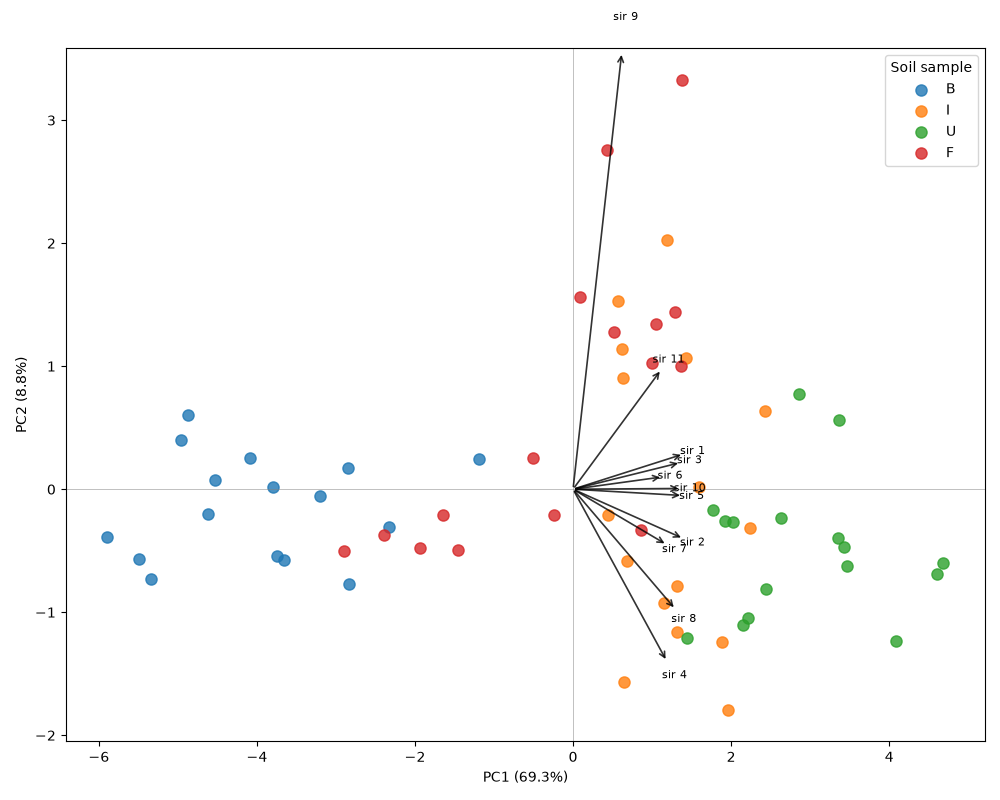

In [8]:
features = [
    # 'br_mg_per_g_h', 
    'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 
    'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h'
]

plot = perform_2d_pca(df=data.microresp, features=features)
save_plot(plot=plot, name="pca_sir")

### 3D PCA

In [141]:
from geo6.pca import prepare_pca_data, calc_pca, plot_pca, print_pca_loadings, perform_pca

### Microresp


PCA loadings:
                        PC1       PC2       PC3
sir_1_mg_per_g_h   0.339503  0.069482 -0.130587
sir_2_mg_per_g_h   0.339197 -0.097415 -0.143279
sir_3_mg_per_g_h   0.330667  0.052638 -0.161181
sir_4_mg_per_g_h   0.288121 -0.339637  0.015981
sir_5_mg_per_g_h   0.336946 -0.012418 -0.209335
sir_6_mg_per_g_h   0.275546  0.024401  0.668228
sir_7_mg_per_g_h   0.288294 -0.109570 -0.104604
sir_8_mg_per_g_h   0.314625 -0.237056 -0.027890
sir_9_mg_per_g_h   0.149587  0.861792 -0.195924
sir_10_mg_per_g_h  0.331418  0.001480 -0.198100
sir_11_mg_per_g_h  0.271208  0.236473  0.597063


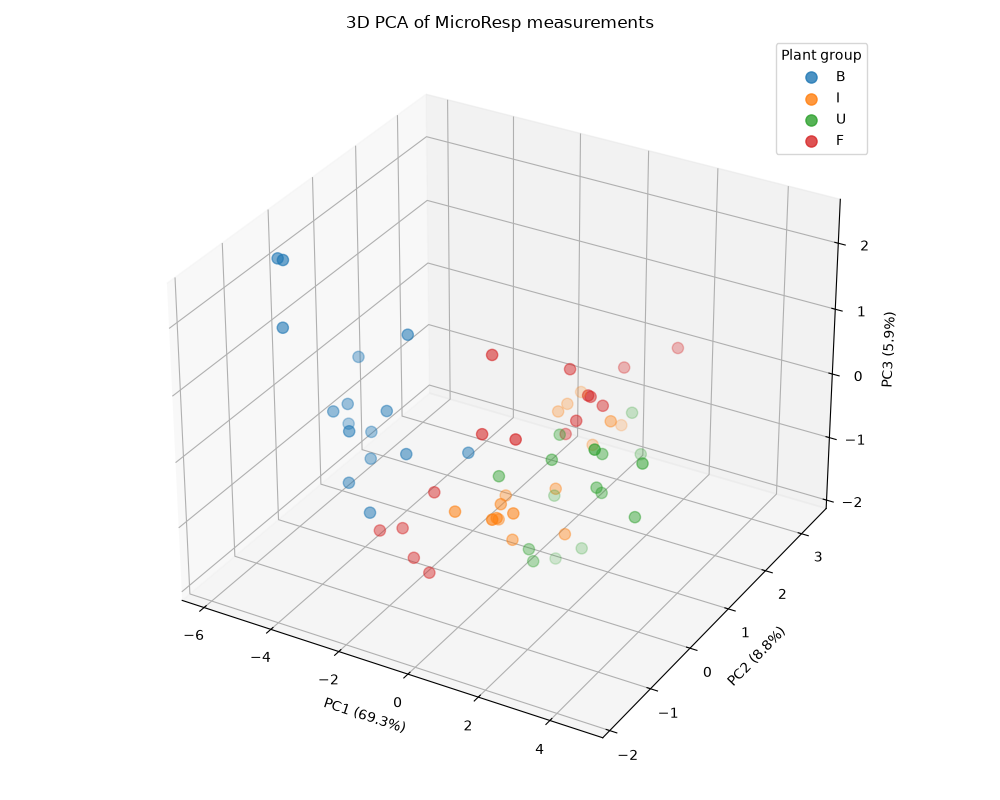

PC1    69.3%
PC2     8.8%
PC3     5.9%
dtype: str
Total variance explained by first 3 PCs: 84.0%


In [142]:
features = [
    # 'br_mg_per_g_h', 
    'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 
    'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h'
]

perform_pca(df=data.microresp, features=features)

## 

In [ ]:
# print(data.dissolved_carbon_nitrogen.columns)
features = ['doc_inc_mg_kg', 'dic_inc_mg_kg',
       'dc_inc_mg_kg', 'dn_inc_mg_kg', 'doc_froz_mg_kg', 'dic_froz_mg_kg',
       'dc_froz_mg_kg', 'dn_froz_mg_kg', 'dcn_inc_ratio', 'dcn_froz_ratio']

df_pca, X_scaled = prepare_pca_data(df=data.dissolved_carbon_nitrogen, features=features)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
corr = X_scaled_df.corr()
print(corr.shape)

if corr is not None:
    plt.close("all")     
    sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag")
    plt.title("Correlation between MicroResp variables")
    plt.show()

else:
       print("corr is None")

In [ ]:
perform_pca(df=data.dissolved_carbon_nitrogen, features=features)

### Nitrification Rate

In [ ]:
nitrification_rate = data.nitrification_rate

# Select response vars
features = [
    # 'nitrate_n_mg_kg_dm', 'ammonium_n_mg_kg_dm', 
    'pnr_0_mg_per_kg_h_dm', 'pnr_0_ste',
    'pnr_W_mg_per_kg_h_dm', 'pnr_W_ste', 
    'pnr_F_mg_per_kg_h_dm', 'pnr_F_ste', 
    'pnr_I_mg_per_kg_h_dm', 'pnr_I_ste',
    'pnr_U_mg_per_kg_h_dm', 'pnr_U_ste'
]

df_pca, X_scaled = prepare_pca_data(df=nitrification_rate, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

## All

In [ ]:
data.cation_exchange_capacity.columns

In [ ]:
from functools import reduce
from dataclasses import fields

field_names = [field.name for field in fields(data)]
dfs = [getattr(data, name) for name in field_names]

keys = ['sample', 'type', 'subrep', 'group']

df_merged = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on=keys,
        how="outer",
        validate="one_to_one",
    ),
    dfs,
)

In [ ]:
# Select response vars
features = df_merged.drop(columns=['sample', 'type', 'subrep', 'group']).columns.to_list()

df_pca, X_scaled = prepare_pca_data(df=df_merged, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

In [ ]:
import plotly.graph_objects as go

# Sample scores
scores = df_scores.copy()

# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
)

fig = go.Figure()

# Plot samples, colored by plant group
for group in scores["sample"].unique():
    subset = scores[scores["sample"] == group]

    fig.add_trace(go.Scatter3d(
        x=subset["PC1"],
        y=subset["PC2"],
        z=subset["PC3"],
        mode="markers",
        name=f"Group {group}",
        marker=dict(size=5),
    ))

# Scale loading vectors for visibility alongside sample scores
scale = scores[["PC1", "PC2", "PC3"]].abs().max().max()

for parameter, row in loadings.iterrows():
    x, y, z = row[["PC1", "PC2", "PC3"]] * scale

    fig.add_trace(go.Scatter3d(
        x=[0, x],
        y=[0, y],
        z=[0, z],
        mode="lines+text",
        name=parameter,
        text=["", parameter],
        textposition="top center",
        line=dict(width=4),
        showlegend=False,
        hovertemplate=f"{parameter}<extra></extra>",
    ))

fig.update_layout(
    title="3D PCA biplot: MicroResp measurements",
    scene=dict(
        xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
        yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
        zaxis_title=f"PC3 ({pca.explained_variance_ratio_[2]:.1%})",
    ),
    legend_title="Plant group",
)

fig.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
)

# The three PC combinations
pc_pairs = [
    ("PC1", "PC2"),
    ("PC1", "PC3"),
    ("PC2", "PC3"),
]

# Scale arrows for visibility alongside sample scores
score_max = df_scores[["PC1", "PC2", "PC3"]].abs().max().max()
loading_max = loadings.abs().to_numpy().max()
arrow_scale = score_max / loading_max * 0.7

for pc_x, pc_y in pc_pairs:
    fig = go.Figure()

    # Plot samples, colored by plant group
    for group in df_scores["sample"].unique():
        subset = df_scores[df_scores["sample"] == group]

        fig.add_trace(go.Scatter(
            x=subset[pc_x],
            y=subset[pc_y],
            mode="markers",
            name=f"Group {group}",
            marker=dict(size=8, opacity=0.8),
            hovertemplate=(
                f"Group: {group}<br>"
                f"{pc_x}: %{{x:.2f}}<br>"
                f"{pc_y}: %{{y:.2f}}"
                "<extra></extra>"
            ),
        ))

    # Plot parameter loading arrows
    for parameter, row in loadings.iterrows():
        x = row[pc_x] * arrow_scale
        y = row[pc_y] * arrow_scale

        # Draw arrow from origin to loading position
        fig.add_annotation(
            x=x,
            y=y,
            ax=0,
            ay=0,
            xref="x",
            yref="y",
            axref="x",
            ayref="y",
            showarrow=True,
            arrowhead=2,
            arrowsize=1,
            arrowwidth=1.5,
        )

        # Place feature name at the arrow tip
        fig.add_trace(go.Scatter(
            x=[x],
            y=[y],
            mode="text",
            text=[parameter],
            textposition="top center",
            textfont=dict(size=10),
            showlegend=False,
            hoverinfo="skip",
        ))

    # Axis labels include explained variance
    x_idx = int(pc_x[-1]) - 1
    y_idx = int(pc_y[-1]) - 1

    fig.update_layout(
        title=f"PCA biplot: {pc_x} vs. {pc_y}",
        xaxis_title=(
            f"{pc_x} "
            f"({pca.explained_variance_ratio_[x_idx]:.1%} variance)"
        ),
        yaxis_title=(
            f"{pc_y} "
            f"({pca.explained_variance_ratio_[y_idx]:.1%} variance)"
        ),
        template="plotly_white",
        width=1000,
        height=750,
        hovermode="closest",
    )

    # Equal axis scaling makes arrow directions easier to compare
    fig.update_yaxes(scaleanchor="x", scaleratio=1)

    fig.show()

## Else

In [143]:
copper = data.copper
copper_sub = copper[["sample", "cu_ex_ug_kg_dm", "cu_org_ug_kg_dm", "cu_red_ug_kg_dm"]]


copper_agg = (
    copper_sub
    .groupby("sample")
    .agg(
        ["mean", "std"]
    )
    .reset_index()
)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_23192\2136735052.py:1: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  data_cols = copper_agg.drop(columns="sample").columns.to_list()


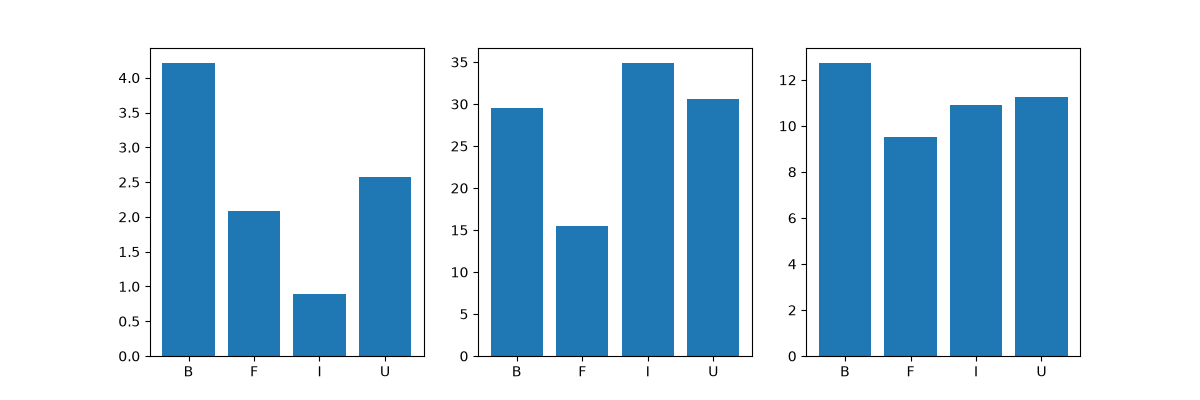

In [144]:
data_cols = copper_agg.drop(columns="sample").columns.to_list()

mean_cols = [col[0] for col in data_cols if col[1] == "mean"]
std_cols = [col[0] for col in data_cols if col[1] == "std"]


fig, axs = plt.subplots(figsize=(12, 4), ncols=3)

for i, col in enumerate(mean_cols):
    
    axs[i].bar(
        x=copper_agg["sample"],
        height=copper_agg[col]["mean"]
    )